# 01 · Ingestion and the level-0 team-strength baseline

Methodology v0.2, build-order steps 1–2: load the raw CSVs into the §2.1 tables, then fit the §7 team-strength model through the §15.1 rolling-origin harness. Every later layer (player effects, style, matchups) has to beat this baseline out of sample.

**Splits (fixed before looking at results).** Rounds 1–10 of 2025/26 are warm-up only, since there is no earlier season to seed ratings. Tuning: 2025/26 rounds 11–24 (140 matches). Test: 2025/26 rounds 25–38 plus 2026/27 rounds 1–5 (190 matches). Each match is predicted from a model refit on matches played strictly before its date.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

import run_l0

## 1. Load the processed tables

The raw scraped files are not redistributed (see the README). `src/ingest.py` documents every cleaning rule (methodology §2.6) and rebuilds these tables from the raw files; here we load the published processed tables.

In [2]:
P = ROOT / "data" / "processed"
tables = {name: pd.read_parquet(P / f"{name}.parquet") for name in
          ["matches", "player_match", "shots", "network_nodes", "network_edges", "match_events"]}
{name: df.shape for name, df in tables.items()}

{'matches': (430, 16),
 'player_match': (17187, 59),
 'shots': (10941, 30),
 'network_nodes': (13030, 20),
 'network_edges': (93507, 6),
 'match_events': (7166, 6)}

In [3]:
pm = tables["player_match"]
print("player-match rows:", len(pm), "| appeared:", int(pm.played.sum()), "| unused subs:", int((~pm.played).sum()))
tables["matches"].groupby(["season", "network_source"]).size().rename("matches").to_frame()

player-match rows: 17187 | appeared: 13030 | unused subs: 4157


matches
season    network_source         
2025/2026 A                   250
          B                   130
2026/2027 C                    50

## 2. Tuning grid

Half-life of the match weights and ridge strength, scored on the tuning period only. The target is npxG, so npxG deviance is the primary criterion; RPS is the tie-breaker.

In [4]:
grid = pd.read_csv(ROOT / "reports" / "team_strength_grid.csv")
g = grid[grid.response == "npxg"]
print("npxG deviance on the tuning period (rows: half-life in days, columns: ridge)")
g.pivot(index="half_life", columns="ridge", values="tune_npxg_dev").round(4)

npxG deviance on the tuning period (rows: half-life in days, columns: ridge)


ridge,0.5,1.0,2.0,4.0,8.0
half_life,,,,,
30.0,0.431,0.420,0.412,0.411,0.418
60.0,0.422,0.415,0.408,0.405,0.409
90.0,0.420,0.414,0.407,0.403,0.406
120.0,0.420,0.414,0.407,0.403,0.405
180.0,0.419,0.414,0.407,0.403,0.404
270.0,0.419,0.414,0.407,0.403,0.403
365.0,0.419,0.414,0.408,0.403,0.403
inf,0.419,0.414,0.408,0.403,0.402


In [5]:
print("RPS on the tuning period")
g.pivot(index="half_life", columns="ridge", values="tune_rps").round(4)

RPS on the tuning period


ridge,0.5,1.0,2.0,4.0,8.0
half_life,,,,,
30.0,0.210,0.210,0.211,0.213,0.217
60.0,0.209,0.208,0.209,0.210,0.213
90.0,0.208,0.208,0.208,0.209,0.212
120.0,0.208,0.208,0.208,0.209,0.211
180.0,0.208,0.208,0.208,0.209,0.211
270.0,0.208,0.208,0.208,0.209,0.210
365.0,0.208,0.208,0.208,0.208,0.210
inf,0.208,0.208,0.208,0.208,0.210


The surface is flat once the half-life passes ~180 days: with just over one season of data, decay barely matters. Ridge 4 minimises deviance at every half-life of 120 days or more. **Chosen: half-life 270 days, ridge 4** (deviance within 0.0002 of the grid minimum, RPS within 0.0006 of the best). Revisit when more seasons are added.

## 3. Test-period results

In [6]:
res = run_l0.main()
res["table"].round(4)

,model,n,rps,log_loss,npxg_deviance
0,"L0 (npxG ratings, Dixon–Coles)",190,0.209,1.043,0.343
1,L0 without Dixon–Coles,190,0.209,1.047,0.343
2,Goals ratings,190,0.211,1.050,0.346
3,Base rates,190,0.229,1.100,NaN


In [7]:
res['comps'].round(4)

,comparison,metric,diff,ci_low,ci_high
0,"L0 (npxG ratings, Dixon–Coles) minus L0 withou...",rps,-3.000e-04,-0.001,7.000e-04
1,"L0 (npxG ratings, Dixon–Coles) minus L0 withou...",log_loss,-4.100e-03,-0.015,6.500e-03
2,"L0 (npxG ratings, Dixon–Coles) minus Goals rat...",rps,-1.900e-03,-0.009,5.400e-03
3,"L0 (npxG ratings, Dixon–Coles) minus Goals rat...",log_loss,-7.400e-03,-0.029,1.450e-02
4,"L0 (npxG ratings, Dixon–Coles) minus Base rates",rps,-2.050e-02,-0.031,-9.600e-03
5,"L0 (npxG ratings, Dixon–Coles) minus Base rates",log_loss,-5.710e-02,-0.088,-2.460e-02


Negative differences favour L0. L0 clearly beats the base-rate benchmark on both RPS and log-loss (95% intervals exclude zero). It beats a model with the same structure fitted on goals, and the version without the Dixon–Coles correction, but those intervals include zero with 190 test matches: the direction supports the xG target, the size isn't established yet.

## 4. Calibration

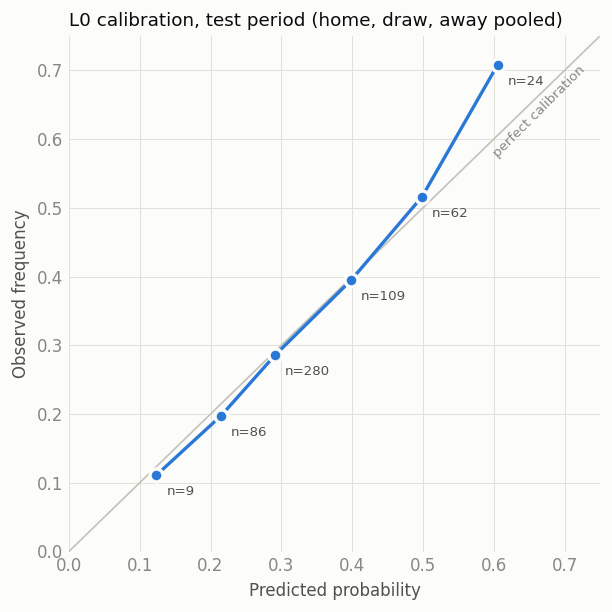

,bin,predicted,observed,n
0,"(0.0, 0.15]",0.124,0.111,9
1,"(0.15, 0.25]",0.215,0.198,86
2,"(0.25, 0.35]",0.291,0.286,280
3,"(0.35, 0.45]",0.398,0.394,109
4,"(0.45, 0.55]",0.499,0.516,62
5,"(0.55, 1.0]",0.606,0.708,24


In [8]:
cal = res["calib"]
fig, ax = plt.subplots(figsize=(5.2, 5.2), dpi=120)
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
ax.plot([0, 0.75], [0, 0.75], color="#c3c2b7", lw=1, zorder=1)
ax.plot(cal.predicted, cal.observed, color="#2a78d6", lw=2, zorder=2)
ax.scatter(cal.predicted, cal.observed, s=60, color="#2a78d6", edgecolor="#fcfcfb", linewidth=2, zorder=3)
for r in cal.itertuples():
    ax.annotate(f"n={r.n}", (r.predicted, r.observed), xytext=(6, -12), textcoords="offset points",
                fontsize=8, color="#52514e")
ax.set_xlim(0, 0.75); ax.set_ylim(0, 0.75)
ax.set_xlabel("Predicted probability", color="#52514e"); ax.set_ylabel("Observed frequency", color="#52514e")
ax.set_title("L0 calibration, test period (home, draw, away pooled)", color="#0b0b0b", fontsize=11, loc="left")
ax.grid(color="#e1e0d9", lw=0.6); ax.set_axisbelow(True)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(colors="#898781", length=0)
ax.text(0.73, 0.70, "perfect calibration", color="#898781", fontsize=8, ha="right", rotation=45, rotation_mode="anchor")
plt.tight_layout(); plt.show()
cal.round(3)

In [9]:
s = res["summary"]
print("Outcome mix, predicted vs observed:", json.dumps(s["outcome_mix"]))
print(f"Dixon–Coles rho range: {s['dc_rho_range'][0]:.3f} to {s['dc_rho_range'][1]:.3f}")
print(f"Goals / xG calibration c range: {s['calib_c_range'][0]:.3f} to {s['calib_c_range'][1]:.3f}")
print(f"Home advantage (npxG multiplier): {s['home_advantage_multiplier']:.3f}")
print(f"Rolling-five sanity check (§7.2): corr(model npxG diff, last-5 npxG diff) = {s['rolling_five_corr']:.2f} over {s['rolling_five_n']} matches")

Outcome mix, predicted vs observed: {"predicted": {"home": 0.421, "draw": 0.277, "away": 0.301}, "observed": {"home": 0.384, "draw": 0.295, "away": 0.321}}
Dixon–Coles rho range: -0.192 to 0.017
Goals / xG calibration c range: 0.963 to 1.043
Home advantage (npxG multiplier): 1.247
Rolling-five sanity check (§7.2): corr(model npxG diff, last-5 npxG diff) = 0.55 over 324 matches


Calibration is close across the range. Home wins are slightly over-predicted in the test period (0.42 predicted vs 0.38 observed), within what 190 matches can resolve; watch it as data accumulates. The Dixon–Coles correction, estimated as of each date, lifts the predicted draw rate from 0.25 to 0.28 (observed 0.30).

## 5. Current ratings

As of the day after the last match in the data (2026/27 round 5). Values are expected npxG per match against an average opponent at a neutral venue.

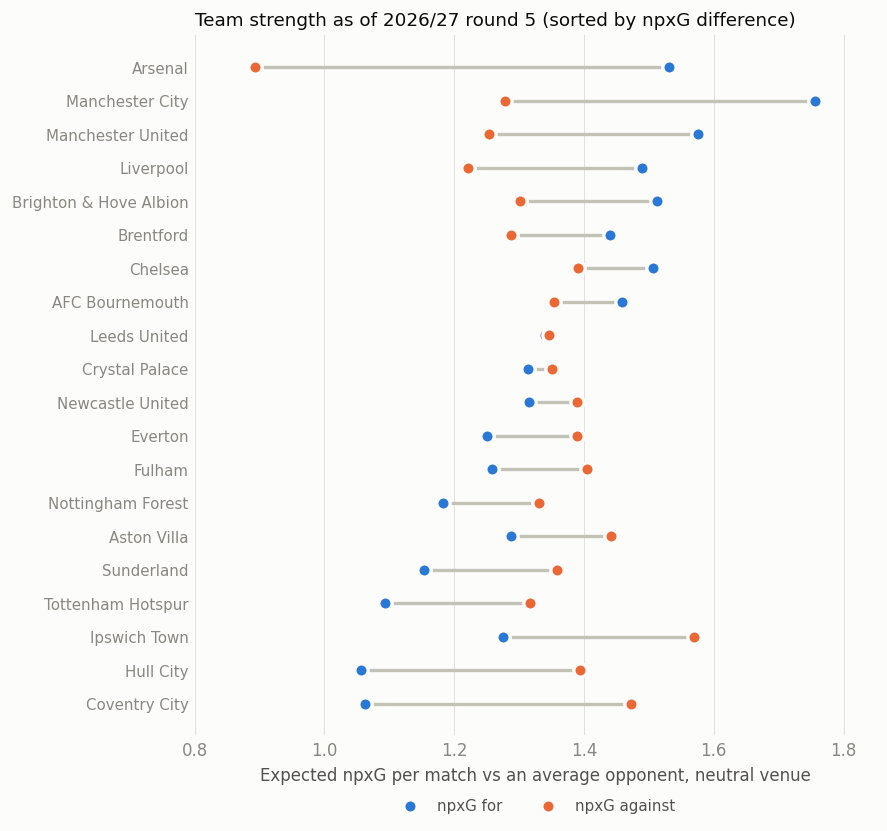

,team,att,def,npxg_for_per_match,npxg_against_per_match,npxg_diff_per_match
0,Arsenal,0.142,0.397,1.530,0.893,0.638
1,Manchester City,0.279,0.038,1.756,1.278,0.477
2,Manchester United,0.171,0.058,1.576,1.253,0.322
3,Liverpool,0.114,0.084,1.489,1.221,0.268
4,Brighton & Hove Albion,0.131,0.020,1.513,1.301,0.212
5,Brentford,0.081,0.030,1.440,1.288,0.152
6,Chelsea,0.126,-0.047,1.506,1.391,0.114
7,AFC Bournemouth,0.094,-0.020,1.459,1.354,0.105
8,Leeds United,0.009,-0.013,1.340,1.346,-0.006
9,Crystal Palace,-0.011,-0.017,1.314,1.351,-0.037


In [10]:
r = res["ratings"].sort_values("npxg_diff_per_match")
fig, ax = plt.subplots(figsize=(7.5, 7), dpi=120)
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
y = np.arange(len(r))
ax.hlines(y, r.npxg_against_per_match, r.npxg_for_per_match, color="#c3c2b7", lw=2, zorder=1)
ax.scatter(r.npxg_for_per_match, y, s=64, color="#2a78d6", edgecolor="#fcfcfb", linewidth=2, zorder=3, label="npxG for")
ax.scatter(r.npxg_against_per_match, y, s=64, color="#eb6834", edgecolor="#fcfcfb", linewidth=2, zorder=3, label="npxG against")
ax.set_yticks(y); ax.set_yticklabels(r.team, color="#0b0b0b", fontsize=9)
ax.set_xlabel("Expected npxG per match vs an average opponent, neutral venue", color="#52514e")
ax.set_title("Team strength as of 2026/27 round 5 (sorted by npxG difference)", color="#0b0b0b", fontsize=11, loc="left")
ax.grid(axis="x", color="#e1e0d9", lw=0.6); ax.set_axisbelow(True)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(colors="#898781", length=0)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2, labelcolor="#52514e", fontsize=9)
ax.set_xlim(0.8, 1.85)
plt.tight_layout(); plt.show()
res["ratings"].round(3)

Promoted sides start from the mean rating of the three relegated teams and move with their five 2026/27 matches, so their ratings are the least certain. Ratings reflect chance quality, not points: a team can sit well above or below its league position if its finishing or goalkeeping ran hot or cold.

## 6. Next

Build-order step 3: player profiles with shrinkage, recency and possession adjustment (§4.2–4.9), on provisional roles. Every later layer is scored with `run_l0`'s harness against the L0 numbers above.